In [1]:
# =====================================================
# EXPERIMENT 2
# PART 1: DATASET PREPARATION
# HIoT IDS MININET ADAPTATION
# =====================================================


import pandas as pd
import numpy as np


from sklearn.model_selection import train_test_split



print("="*70)
print("EXPERIMENT 2: MININET ADAPTATION DATA PREPARATION")
print("="*70)



# =====================================================
# LOAD TON-IOT DATASET
# =====================================================


print("\nLoading TON-IoT Dataset")


toniot = pd.read_csv(
    "../data/train_test_network.csv"
)


print(
    "TON-IoT Shape:",
    toniot.shape
)



# =====================================================
# LOAD MININET DATASET
# =====================================================


print("\nLoading Mininet Dataset")


mininet = pd.read_csv(
    "mininet_processed.csv"
)


print(
    "Mininet Shape:",
    mininet.shape
)



# =====================================================
# ADD SOURCE INFORMATION
# =====================================================


toniot["source"] = "TON-IoT"

mininet["source"] = "Mininet"



# =====================================================
# CLEAN DATASETS
# =====================================================


print("\nCleaning Datasets")


for df in [toniot, mininet]:


    df.replace(
        "-",
        "unknown",
        inplace=True
    )


    df.fillna(
        "unknown",
        inplace=True
    )



print("Cleaning Completed")



# =====================================================
# DROP UNUSED FEATURES
# =====================================================


drop_columns = [

    "src_ip",
    "dst_ip",

    "src_port",
    "dst_port",

    "ssl_subject",
    "ssl_issuer",

    "http_user_agent",

    "label"

]



for df in [toniot, mininet]:


    df.drop(

        columns=drop_columns,

        inplace=True,

        errors="ignore"

    )



print("\nAfter Feature Removal")


print(
    "TON-IoT:",
    toniot.shape
)


print(
    "Mininet:",
    mininet.shape
)



# =====================================================
# SPLIT MININET DATA
# 70% ADAPTATION + 30% HIDDEN TEST
# =====================================================


print("\nSplitting Mininet Dataset")


mininet_train, mininet_test = train_test_split(

    mininet,

    test_size=0.30,

    random_state=42,

    stratify=mininet["type"]

)



print(
    "Mininet Adaptation Data:",
    mininet_train.shape
)


print(
    "Hidden Mininet Test:",
    mininet_test.shape
)



# =====================================================
# FEATURE ALIGNMENT
# =====================================================


print("\nAligning Features")



common_features = sorted(

    list(

        set(toniot.columns)

        &

        set(mininet_train.columns)

    )

)



toniot = toniot[common_features]

mininet_train = mininet_train[common_features]

mininet_test = mininet_test[common_features]



print(

    "Number of Common Features:",

    len(common_features)

)



# =====================================================
# CREATE FINAL TRAINING AND TEST DATA
# =====================================================


train_data = pd.concat(

    [

        toniot,

        mininet_train

    ],

    ignore_index=True

)



test_data = mininet_test.copy()



print("\nFinal Dataset Shapes")


print(

    "Training Dataset:",

    train_data.shape

)


print(

    "Hidden Mininet Test:",

    test_data.shape

)



# =====================================================
# CHECK CLASS DISTRIBUTION
# =====================================================


print("\nTraining Class Distribution")


print(

    train_data["type"].value_counts()

)



print("\nHidden Mininet Test Distribution")


print(

    test_data["type"].value_counts()

)



print("\n")

print("="*70)

print("PART 1 COMPLETED")

print("="*70)

EXPERIMENT 2: MININET ADAPTATION DATA PREPARATION

Loading TON-IoT Dataset
TON-IoT Shape: (211043, 44)

Loading Mininet Dataset
Mininet Shape: (336, 36)

Cleaning Datasets
Cleaning Completed

After Feature Removal
TON-IoT: (211043, 37)
Mininet: (336, 37)

Splitting Mininet Dataset
Mininet Adaptation Data: (235, 37)
Hidden Mininet Test: (101, 37)

Aligning Features
Number of Common Features: 37

Final Dataset Shapes
Training Dataset: (211278, 37)
Hidden Mininet Test: (101, 37)

Training Class Distribution
type
normal        50149
ddos          20033
scanning      20031
dos           20016
backdoor      20006
injection     20000
password      20000
ransomware    20000
xss           20000
mitm           1043
Name: count, dtype: int64

Hidden Mininet Test Distribution
type
normal      64
ddos        14
scanning    13
dos          7
backdoor     3
Name: count, dtype: int64


PART 1 COMPLETED


In [2]:
# =====================================================
# EXPERIMENT 2
# PART 2: DATA PREPROCESSING
# HIoT IDS MININET ADAPTATION
# =====================================================


import pandas as pd
import numpy as np


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)


from sklearn.compose import ColumnTransformer



print("="*70)
print("EXPERIMENT 2: PREPROCESSING")
print("="*70)



# =====================================================
# SEPARATE FEATURES AND LABEL
# =====================================================


print("\nSeparating Features and Labels")



X_train = train_data.drop(

    "type",

    axis=1

)


y_train = train_data["type"]



X_test = test_data.drop(

    "type",

    axis=1

)


y_test = test_data["type"]



print("\nFeature Shapes")


print(

    "X_train:",

    X_train.shape

)


print(

    "X_test:",

    X_test.shape

)



# =====================================================
# LABEL ENCODING
# =====================================================


print("\nEncoding Labels")



label_encoder = LabelEncoder()



y_train_encoded = label_encoder.fit_transform(

    y_train

)



y_test_encoded = label_encoder.transform(

    y_test

)



print("\nClasses")

print(

    label_encoder.classes_

)



# =====================================================
# IDENTIFY FEATURE TYPES
# =====================================================


print("\nIdentifying Feature Types")



categorical_columns = X_train.select_dtypes(

    include="object"

).columns.tolist()



numerical_columns = X_train.select_dtypes(

    exclude="object"

).columns.tolist()



print(

    "Categorical Features:",

    len(categorical_columns)

)



print(

    "Numerical Features:",

    len(numerical_columns)

)



# =====================================================
# FIX DATA TYPES
# =====================================================


print("\nFixing Data Types")



# categorical conversion

for col in categorical_columns:


    X_train[col] = (

        X_train[col]

        .astype(str)

    )


    X_test[col] = (

        X_test[col]

        .astype(str)

    )




# numerical conversion

for col in numerical_columns:


    X_train[col] = pd.to_numeric(

        X_train[col],

        errors="coerce"

    )


    X_test[col] = pd.to_numeric(

        X_test[col],

        errors="coerce"

    )




# replace invalid numerical values

X_train[numerical_columns] = (

    X_train[numerical_columns]

    .fillna(0)

)



X_test[numerical_columns] = (

    X_test[numerical_columns]

    .fillna(0)

)



print(

    "Datatype Correction Completed"

)



# =====================================================
# BUILD PREPROCESSOR
# =====================================================


print("\nBuilding Preprocessor")



preprocessor = ColumnTransformer(

    transformers=[


        (

            "cat",

            OneHotEncoder(

                handle_unknown="ignore",

                sparse_output=False

            ),

            categorical_columns

        ),



        (

            "num",

            StandardScaler(),

            numerical_columns

        )

    ]

)



# =====================================================
# FIT ONLY TRAINING DATA
# =====================================================


print("\nFitting Preprocessor")



X_train_processed = preprocessor.fit_transform(

    X_train

)



print(

    "Training Transformation Completed"

)



# =====================================================
# TRANSFORM HIDDEN MININET TEST
# =====================================================


print("\nTransforming Hidden Mininet Test")



X_test_processed = preprocessor.transform(

    X_test

)



print("\nProcessed Shapes")


print(

    "Training:",

    X_train_processed.shape

)



print(

    "Hidden Mininet Test:",

    X_test_processed.shape

)



print("\n")

print("="*70)

print("PART 2 COMPLETED")

print("="*70)

EXPERIMENT 2: PREPROCESSING

Separating Features and Labels

Feature Shapes
X_train: (211278, 36)
X_test: (101, 36)

Encoding Labels

Classes
['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

Identifying Feature Types
Categorical Features: 22
Numerical Features: 14

Fixing Data Types
Datatype Correction Completed

Building Preprocessor

Fitting Preprocessor


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_22148\445059031.py:134: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Training Transformation Completed

Transforming Hidden Mininet Test

Processed Shapes
Training: (211278, 929)
Hidden Mininet Test: (101, 929)


PART 2 COMPLETED


EXPERIMENT 2: RANDOM FOREST
HIDDEN MININET EVALUATION

Building Random Forest Model

Training Random Forest
Training Completed

Predicting Hidden Mininet Traffic


RANDOM FOREST RESULTS
Accuracy     : 0.6336633663366337
Precision    : 0.5760257526521974
Recall       : 0.6336633663366337
Weighted F1  : 0.6016217750807339
Macro F1     : 0.2663082437275986

Classification Report
              precision    recall  f1-score   support

    backdoor     0.0000    0.0000    0.0000         3
        ddos     0.3529    0.4286    0.3871        14
         dos     0.0000    0.0000    0.0000         7
   injection     0.0000    0.0000    0.0000         0
        mitm     0.0000    0.0000    0.0000         0
      normal     0.8028    0.8906    0.8444        64
    password     0.0000    0.0000    0.0000         0
  ransomware     0.0000    0.0000    0.0000         0
    scanning     0.1429    0.0769    0.1000        13
         xss     0.0000    0.0000    0.0000         0

    accuracy             

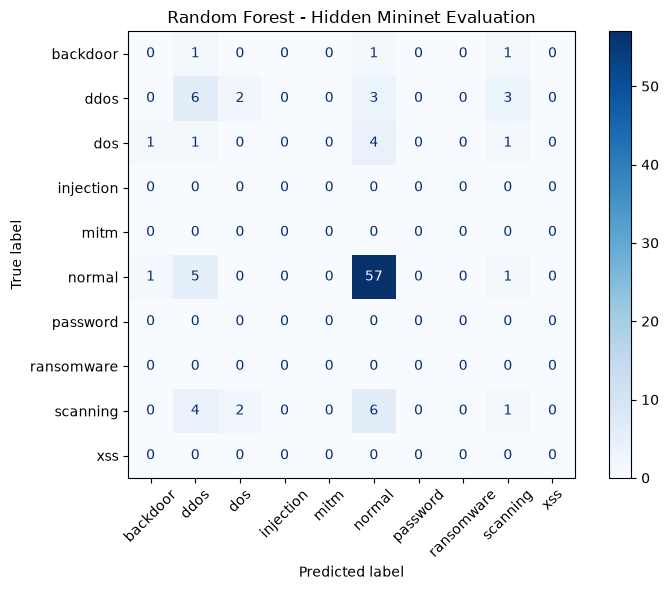



PART 3 COMPLETED


In [3]:
# =====================================================
# EXPERIMENT 2
# PART 3: RANDOM FOREST
# HIoT IDS MININET ADAPTATION
# =====================================================


import numpy as np
import matplotlib.pyplot as plt


from sklearn.ensemble import RandomForestClassifier


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report,

    confusion_matrix,

    ConfusionMatrixDisplay

)



print("="*70)

print("EXPERIMENT 2: RANDOM FOREST")

print("HIDDEN MININET EVALUATION")

print("="*70)



# =====================================================
# BUILD RANDOM FOREST MODEL
# SAME MODEL CONFIGURATION
# =====================================================


print("\nBuilding Random Forest Model")



rf = RandomForestClassifier(

    n_estimators=200,

    random_state=42,

    n_jobs=-1

)



# =====================================================
# TRAIN MODEL
# =====================================================


print("\nTraining Random Forest")



rf.fit(

    X_train_processed,

    y_train_encoded

)



print(

    "Training Completed"

)



# =====================================================
# PREDICTION
# =====================================================


print("\nPredicting Hidden Mininet Traffic")



rf_pred = rf.predict(

    X_test_processed

)



# =====================================================
# METRICS
# =====================================================


accuracy = accuracy_score(

    y_test_encoded,

    rf_pred

)



precision = precision_score(

    y_test_encoded,

    rf_pred,

    average="weighted",

    zero_division=0

)



recall = recall_score(

    y_test_encoded,

    rf_pred,

    average="weighted",

    zero_division=0

)



weighted_f1 = f1_score(

    y_test_encoded,

    rf_pred,

    average="weighted",

    zero_division=0

)



macro_f1 = f1_score(

    y_test_encoded,

    rf_pred,

    average="macro",

    zero_division=0

)



print("\n")

print("="*70)

print("RANDOM FOREST RESULTS")

print("="*70)



print(

    "Accuracy     :", 

    accuracy

)


print(

    "Precision    :", 

    precision

)


print(

    "Recall       :", 

    recall

)


print(

    "Weighted F1  :", 

    weighted_f1

)


print(

    "Macro F1     :", 

    macro_f1

)



# =====================================================
# CLASSIFICATION REPORT
# =====================================================


print("\nClassification Report")



print(

    classification_report(

        y_test_encoded,

        rf_pred,

        labels=np.arange(

            len(label_encoder.classes_)

        ),

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)



# =====================================================
# CONFUSION MATRIX
# =====================================================


cm = confusion_matrix(

    y_test_encoded,

    rf_pred,

    labels=np.arange(

        len(label_encoder.classes_)

    )

)



fig, ax = plt.subplots(

    figsize=(8,6)

)



disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=label_encoder.classes_

)



disp.plot(

    cmap="Blues",

    xticks_rotation=45,

    ax=ax

)



plt.title(

    "Random Forest - Hidden Mininet Evaluation"

)



plt.tight_layout()

plt.show()



print("\n")

print("="*70)

print("PART 3 COMPLETED")

print("="*70)

EXPERIMENT 2: XGBOOST
HIDDEN MININET EVALUATION

Building XGBoost Model

Training XGBoost Model
Training Completed

Predicting Hidden Mininet Traffic


XGBOOST RESULTS
Accuracy     : 0.6534653465346535
Precision    : 0.5393422100830773
Recall       : 0.6534653465346535
Weighted F1  : 0.5766728990779872
Macro F1     : 0.2565388989230049

Classification Report
              precision    recall  f1-score   support

    backdoor     0.0000    0.0000    0.0000         3
        ddos     0.5000    0.2857    0.3636        14
         dos     0.0000    0.0000    0.0000         7
   injection     0.0000    0.0000    0.0000         0
        mitm     0.0000    0.0000    0.0000         0
      normal     0.7011    0.9531    0.8079        64
    password     0.0000    0.0000    0.0000         0
  ransomware     0.0000    0.0000    0.0000         0
    scanning     0.2000    0.0769    0.1111        13
         xss     0.0000    0.0000    0.0000         0

    accuracy                         0.6535

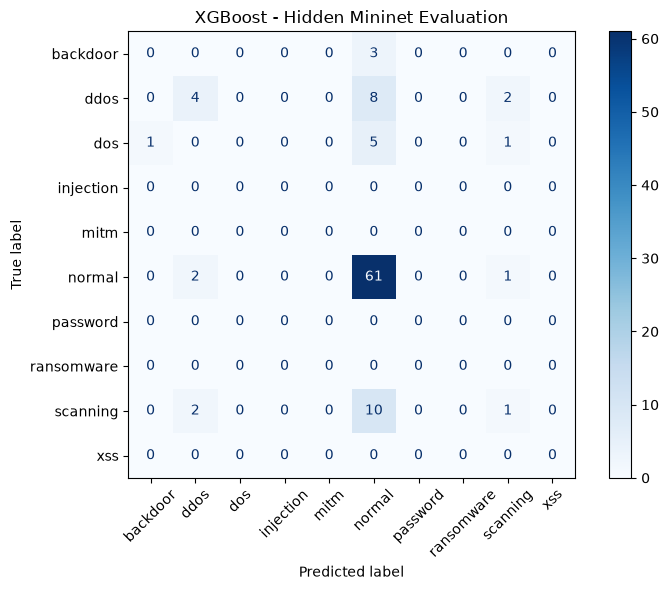


Top 20 Feature Importance
1. Feature 1 : 0.133567
2. Feature 869 : 0.115407
3. Feature 749 : 0.113514
4. Feature 11 : 0.068907
5. Feature 7 : 0.067079
6. Feature 0 : 0.055700
7. Feature 870 : 0.041835
8. Feature 17 : 0.032181
9. Feature 927 : 0.031560
10. Feature 926 : 0.030207
11. Feature 5 : 0.025970
12. Feature 928 : 0.023858
13. Feature 9 : 0.021312
14. Feature 919 : 0.017596
15. Feature 716 : 0.015401
16. Feature 866 : 0.012366
17. Feature 2 : 0.011419
18. Feature 888 : 0.009938
19. Feature 206 : 0.008093
20. Feature 877 : 0.007924


PART 4 COMPLETED


In [4]:
# =====================================================
# EXPERIMENT 2
# PART 4: XGBOOST
# HIoT IDS MININET ADAPTATION
# =====================================================


import numpy as np
import matplotlib.pyplot as plt


from xgboost import XGBClassifier


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report,

    confusion_matrix,

    ConfusionMatrixDisplay

)



print("="*70)

print("EXPERIMENT 2: XGBOOST")

print("HIDDEN MININET EVALUATION")

print("="*70)



# =====================================================
# BUILD XGBOOST MODEL
# SAME CONFIGURATION AS BASELINE
# =====================================================


print("\nBuilding XGBoost Model")



xgb = XGBClassifier(

    n_estimators=200,

    learning_rate=0.1,

    random_state=42,

    n_jobs=-1,

    objective="multi:softprob",

    eval_metric="mlogloss"

)



# =====================================================
# TRAIN MODEL
# =====================================================


print("\nTraining XGBoost Model")



xgb.fit(

    X_train_processed,

    y_train_encoded

)



print(

    "Training Completed"

)



# =====================================================
# PREDICTION
# =====================================================


print("\nPredicting Hidden Mininet Traffic")



xgb_pred = xgb.predict(

    X_test_processed

)



# =====================================================
# METRICS
# =====================================================


accuracy = accuracy_score(

    y_test_encoded,

    xgb_pred

)



precision = precision_score(

    y_test_encoded,

    xgb_pred,

    average="weighted",

    zero_division=0

)



recall = recall_score(

    y_test_encoded,

    xgb_pred,

    average="weighted",

    zero_division=0

)



weighted_f1 = f1_score(

    y_test_encoded,

    xgb_pred,

    average="weighted",

    zero_division=0

)



macro_f1 = f1_score(

    y_test_encoded,

    xgb_pred,

    average="macro",

    zero_division=0

)



print("\n")

print("="*70)

print("XGBOOST RESULTS")

print("="*70)



print(

    "Accuracy     :", 

    accuracy

)


print(

    "Precision    :", 

    precision

)


print(

    "Recall       :", 

    recall

)


print(

    "Weighted F1  :", 

    weighted_f1

)


print(

    "Macro F1     :", 

    macro_f1

)



# =====================================================
# CLASSIFICATION REPORT
# =====================================================


print("\nClassification Report")



print(

    classification_report(

        y_test_encoded,

        xgb_pred,

        labels=np.arange(

            len(label_encoder.classes_)

        ),

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)



# =====================================================
# CONFUSION MATRIX
# =====================================================


cm = confusion_matrix(

    y_test_encoded,

    xgb_pred,

    labels=np.arange(

        len(label_encoder.classes_)

    )

)



fig, ax = plt.subplots(

    figsize=(8,6)

)



disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=label_encoder.classes_

)



disp.plot(

    cmap="Blues",

    xticks_rotation=45,

    ax=ax

)



plt.title(

    "XGBoost - Hidden Mininet Evaluation"

)



plt.tight_layout()

plt.show()



# =====================================================
# FEATURE IMPORTANCE
# =====================================================


print("\nTop 20 Feature Importance")



importance = xgb.feature_importances_



indices = np.argsort(

    importance

)[::-1]



for i in range(

    min(20, len(indices))

):

    print(

        f"{i+1}. Feature {indices[i]} : {importance[indices[i]]:.6f}"

    )



print("\n")

print("="*70)

print("PART 4 COMPLETED")

print("="*70)